<a href="https://colab.research.google.com/github/sejal-oli7/Elevvo-Machine-Learning-Internship/blob/main/customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42



In [6]:
CSV_PATH  = "/content/Mall_Customers.csv"

df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [9]:
#Data Cleaning
df = df.rename(columns={

    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending",
})
print(df.columns.tolist())
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df.describe()

['CustomerID', 'Gender', 'Age', 'Income', 'Spending']
Missing values:
 CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Duplicates: 0


,CustomerID,Age,Income,Spending
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


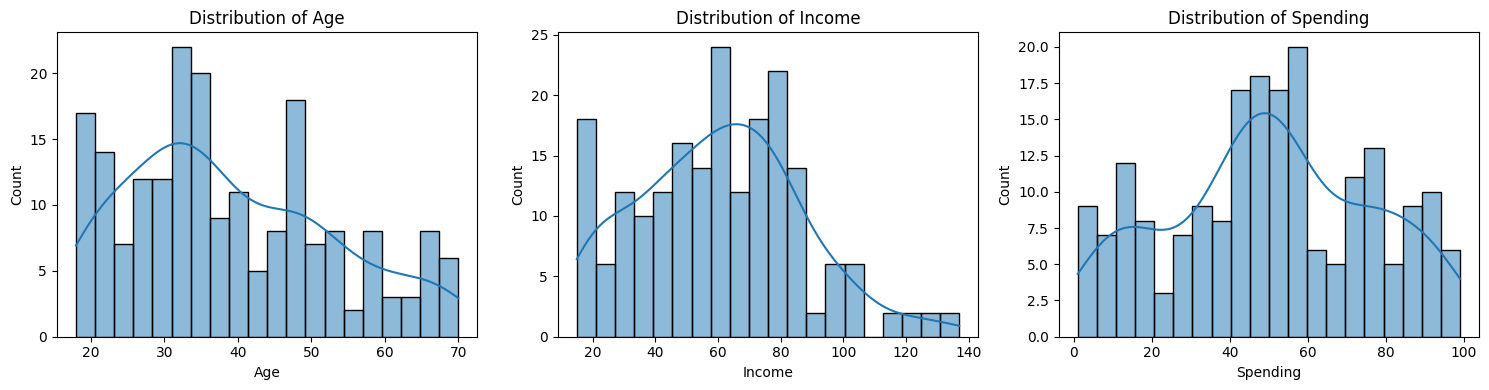

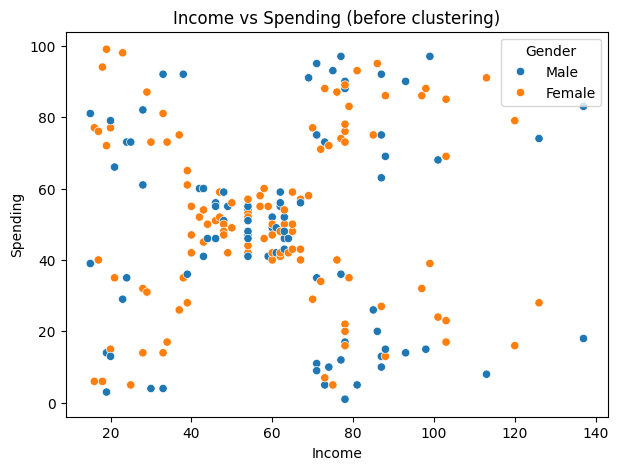

In [10]:
#visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Income", "Spending"]):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Income", y="Spending", hue="Gender")
plt.title("Income vs Spending (before clustering)")
plt.show()

In [11]:
#scaling
X = df[["Income", "Spending"]].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Mean:", X_scaled.mean(axis=0).round(2), "Std:", X_scaled.std(axis=0).round(2))

Mean: [-0. -0.] Std: [1. 1.]


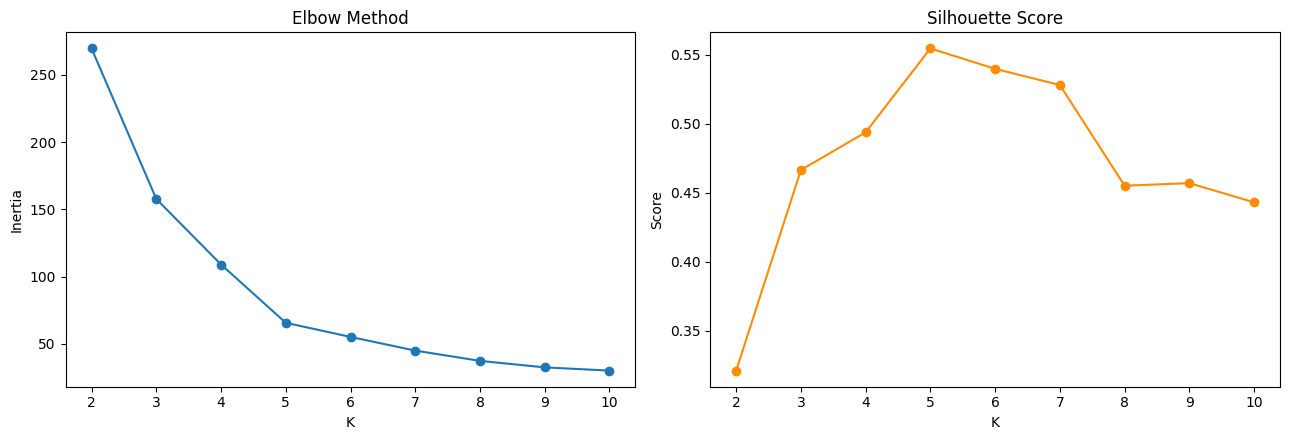

In [13]:
#Optimal K (Elbow + Silhouette)
k_range = range(2, 11)
inertias, sil_scores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_range, inertias, "o-")
axes[0].set_title("Elbow Method"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[1].plot(k_range, sil_scores, "o-", color="darkorange")
axes[1].set_title("Silhouette Score"); axes[1].set_xlabel("K"); axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()


Silhouette: 0.555


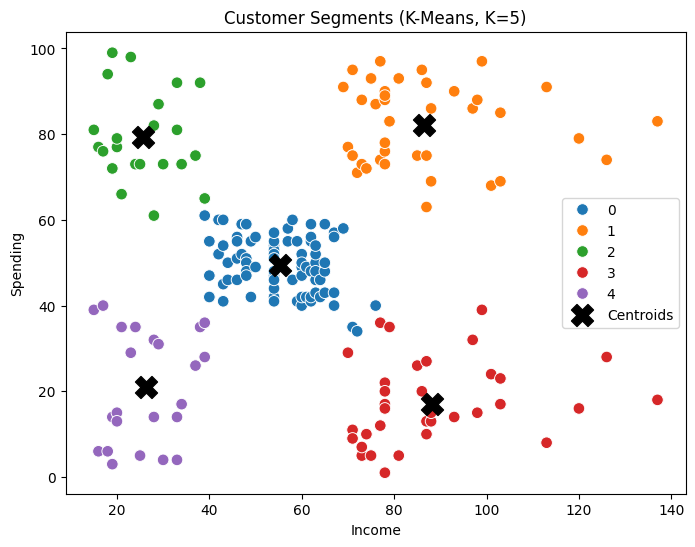

In [15]:
#Final K-Means (K=5) ra 2D plot
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("Silhouette:", round(silhouette_score(X_scaled, df["Cluster"]), 3))

centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Income", y="Spending", hue="Cluster",
                palette="tab10", s=70)
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, c="black", marker="X", label="Centroids")
plt.title("Customer Segments (K-Means, K=5)")
plt.legend()
plt.show()

,Customers,Avg_Income,Avg_Spending,Avg_Age
Cluster,,,,
0,81,55.30,49.52,42.72
1,39,86.54,82.13,32.69
2,22,25.73,79.36,25.27
3,35,88.20,17.11,41.11
4,23,26.30,20.91,45.22


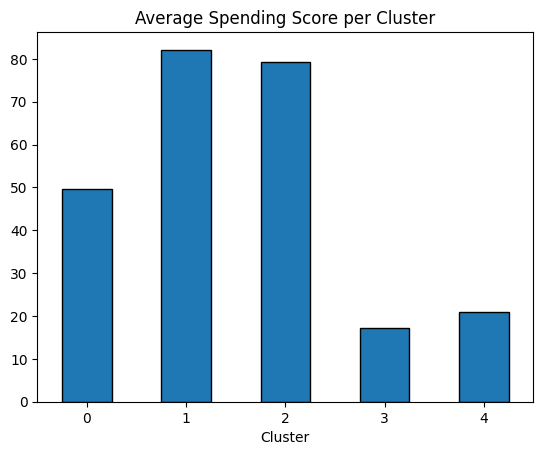

In [16]:
# Bonus, average spending per cluster
profile = df.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Avg_Income=("Income", "mean"),
    Avg_Spending=("Spending", "mean"),
    Avg_Age=("Age", "mean")
).round(2)
display(profile)

profile["Avg_Spending"].plot(kind="bar", edgecolor="black")
plt.title("Average Spending Score per Cluster")
plt.xticks(rotation=0)
plt.show()

In [19]:
segment_names = {
    0: "Standard customers",
    1: "Target customers (high income, high spending)",
    2: "Impulsive young spenders",
    3: "Careful high earners",
    4: "Budget customers",
}
df["Segment"] = df["Cluster"].map(segment_names)
df.groupby("Segment")[["Income", "Spending", "Age"]].mean().round(1)

,Income,Spending,Age
Segment,,,
Budget customers,26.3,20.9,45.2
Careful high earners,88.2,17.1,41.1
Impulsive young spenders,25.7,79.4,25.3
Standard customers,55.3,49.5,42.7
"Target customers (high income, high spending)",86.5,82.1,32.7


Clusters: 4 | Noise points: 15


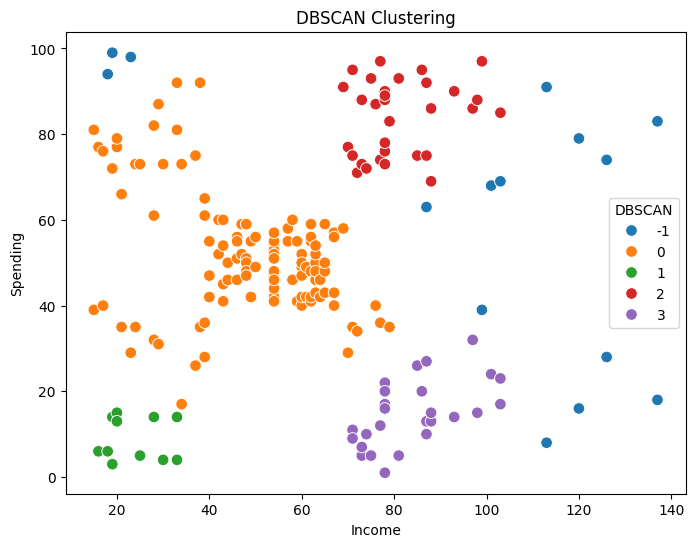

In [17]:
# Bonus, DBSCAN
db = DBSCAN(eps=0.4, min_samples=5)
df["DBSCAN"] = db.fit_predict(X_scaled)
print("Clusters:", len(set(df["DBSCAN"])) - (1 if -1 in df["DBSCAN"].values else 0),
      "| Noise points:", (df["DBSCAN"] == -1).sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Income", y="Spending", hue="DBSCAN", palette="tab10", s=70)
plt.title("DBSCAN Clustering")
plt.show()

In [20]:
mask = df["DBSCAN"] != -1
print("K-Means silhouette:", round(silhouette_score(X_scaled, df["Cluster"]), 3))
print("DBSCAN silhouette (noise excluded):", round(silhouette_score(X_scaled[mask], df.loc[mask, "DBSCAN"]), 3))

K-Means silhouette: 0.555
DBSCAN silhouette (noise bahek): 0.478


In [18]:
df.to_csv("customers_with_clusters.csv", index=False)